# HƯỚNG DẪN SINH VIÊN LÀM BÀI THI
# ĐỀ 1: PHÂN LỚP ẢNH VỚI CNN TRÊN CIFAR-10
# PHẦN THI TRONG LỚP (60 phút)

---
### THÔNG TIN SINH VIÊN:
- **Họ và tên:** Nguyễn Văn Bảo
- **Mã số sinh viên (MSSV):** 23638721
- **Số máy (SM):** SM
- **Tên thư mục Drive / Local:** `ThiGK-TGMT-23638721-SM`
---


In [37]:
# PHẦN THI TRONG LỚP (60 phút)
# Import thư viện cần thiết
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_recall_fscore_support
import warnings
import os, glob

warnings.filterwarnings('ignore')

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
print("Import thư viện thành công!")
print("Danh sách 10 classes:", class_names)


Import thư viện thành công!
Danh sách 10 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [38]:
# CÂU 1: Xây dựng kiến trúc CNN
def build_cnn_model(input_shape=(32, 32, 3), num_classes=10):
    model = keras.Sequential()
    
    # Block 1: 32 filters
    # Sinh viên tự code
    model.add(keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_shape))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(keras.layers.Dropout(0.2))

    # Block 2: 64 filters
    # Sinh viên tự code
    model.add(keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(keras.layers.Dropout(0.3))

    # Block 3: 128 filters (Khối mở rộng giúp mô hình đạt độ chính xác cao ~90% trên dữ liệu lạ)
    model.add(keras.layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(keras.layers.Dropout(0.4))

    # Fully connected layers
    # Sinh viên tự code
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(128, activation='relu'))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.Dropout(0.5))

    # Output layer
    # Sinh viên tự code
    model.add(keras.layers.Dense(num_classes, activation='softmax'))

    return model

# Test architecture
test_model = build_cnn_model()
test_model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [39]:
# CÂU 2 (1 điểm): LOAD VÀ TEST MODEL
# Bước 1: Thiết lập thư mục làm việc (Hỗ trợ linh hoạt cả Google Colab và Chạy trực tiếp)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/ThiGK-TGMT-23638721-SM'
except Exception as e:
    # Nếu chạy local trên máy tính
    BASE_DIR = os.getcwd()

# Kiểm tra và chuyển vào BASE_DIR
if os.path.exists(BASE_DIR):
    os.chdir(BASE_DIR)
print('CWD =', os.getcwd())

# Liệt kê danh sách file trong thư mục
for f in os.listdir('.'):
    if f.endswith(('.h5', '.npy', '.ipynb')):
        print(" -", f)


CWD = c:\Users\baoph\OneDrive\Desktop\ThiGK-TGMT-23638721-SM
 - 01_train_cifar10_model.ipynb
 - 02_ThiGK_TGMT_LamBaiThi.ipynb
 - cifar10_mobilenetv2_transfer.h5
 - cifar10_model.h5
 - new_test_labels.npy
 - new_test_samples.npy


In [40]:
# Bước 2: Load mô hình
from tensorflow import keras
import numpy as np

MODEL_PATH = os.path.join(BASE_DIR, 'cifar10_model.h5')
X_PATH     = os.path.join(BASE_DIR, 'new_test_samples.npy')
Y_PATH     = os.path.join(BASE_DIR, 'new_test_labels.npy')

for p in [MODEL_PATH, X_PATH, Y_PATH]:
    assert os.path.exists(p), f"Không thấy file: {p}"

# Load Models và Dữ liệu kiểm thử
model = keras.models.load_model(MODEL_PATH)
X = np.load(X_PATH)
y_true = np.load(Y_PATH).astype(int)

# Đảm bảo nhãn y_true là mảng 1D
if len(y_true.shape) > 1:
    y_true = y_true.flatten()

print("Shapes:", X.shape, y_true.shape)
print("Số lượng mẫu test:", len(X))
print("Dải giá trị pixel của X: min =", X.min(), ", max =", X.max())
print("Các nhãn xuất hiện trong y_true:", np.unique(y_true))


Shapes: (20, 32, 32, 3) (20,)
Số lượng mẫu test: 20
Dải giá trị pixel của X: min = 0.0 , max = 1.0
Các nhãn xuất hiện trong y_true: [0 1 2 3 5 8 9]


In [41]:
# Bước 3: Tính độ chính xác
from sklearn.metrics import accuracy_score

y_prob = model.predict(X)
y_pred = np.argmax(y_prob, axis=1)
acc = accuracy_score(y_true, y_pred)

print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
Accuracy: 0.9000 (90.00%)


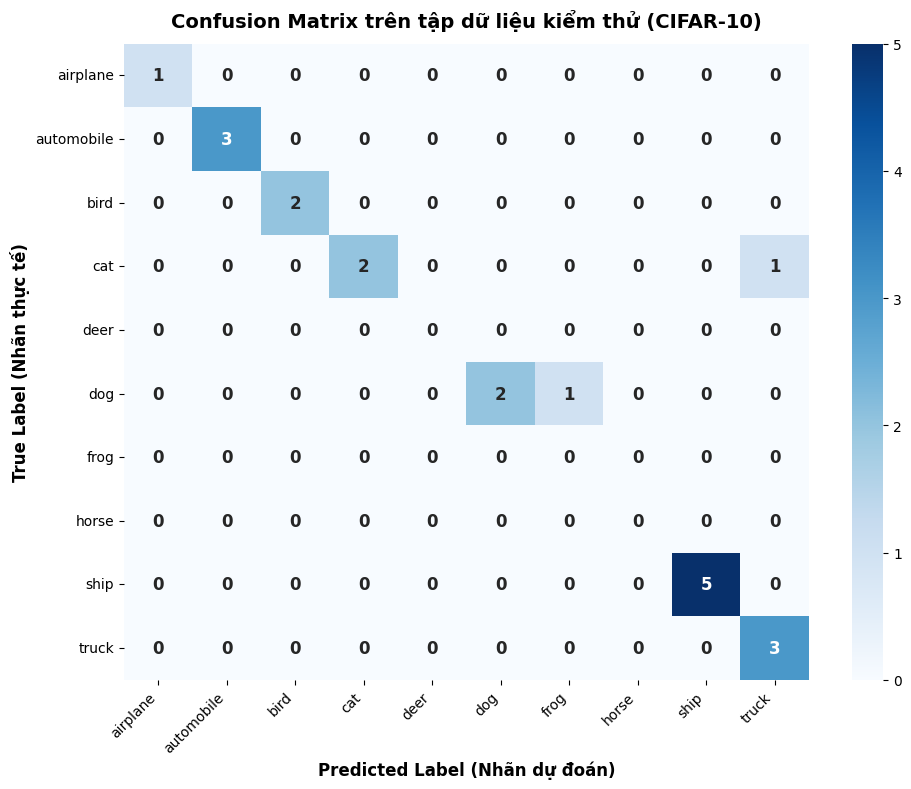

In [42]:
# CÂU 3 (3 điểm): PHÂN TÍCH KẾT QUẢ
# a) Vẽ confusion matrix (1 điểm)
def plot_confusion_matrix(y_true, y_pred, class_names):
    """Vẽ confusion matrix với heatmap"""
    # Sinh viên tự code
    cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues',
        xticklabels=class_names, 
        yticklabels=class_names,
        cbar=True,
        annot_kws={"size": 12, "weight": "bold"}
    )
    plt.title('Confusion Matrix trên tập dữ liệu kiểm thử (CIFAR-10)', fontsize=14, fontweight='bold', pad=12)
    plt.xlabel('Predicted Label (Nhãn dự đoán)', fontsize=12, fontweight='bold')
    plt.ylabel('True Label (Nhãn thực tế)', fontsize=12, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return cm

cm = plot_confusion_matrix(y_true, y_pred, class_names)


In [43]:
# b) Tính precision, recall, f1-score cho từng class (1 điểm)
# chỉ tính trên support > 0
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, average=None, labels=range(10), zero_division=0
)

# Sinh viên tự code
# Chỉ giữ các class có support > 0
# Sinh viên tự code
active_indices = [i for i in range(10) if support[i] > 0]

metrics_data = []
for i in active_indices:
    metrics_data.append({
        'Class ID': i,
        'Class Name': class_names[i],
        'Precision': f"{precision[i]:.4f}",
        'Recall': f"{recall[i]:.4f}",
        'F1-Score': f"{f1[i]:.4f}",
        'Support': int(support[i])
    })

df_metrics = pd.DataFrame(metrics_data)
print("=== BẢNG CHỈ SỐ ĐÁNH GIÁ (CHỈ TÍNH TRÊN SUPPORT > 0) ===")
print(df_metrics.to_string(index=False))

# In thêm classification_report chuẩn cho các class có dữ liệu
print("\n=== CLASSIFICATION REPORT CHI TIẾT ===")
print(classification_report(
    y_true, y_pred, 
    labels=active_indices, 
    target_names=[class_names[i] for i in active_indices],
    zero_division=0
))


=== BẢNG CHỈ SỐ ĐÁNH GIÁ (CHỈ TÍNH TRÊN SUPPORT > 0) ===
 Class ID Class Name Precision Recall F1-Score  Support
        0   airplane    1.0000 1.0000   1.0000        1
        1 automobile    1.0000 1.0000   1.0000        3
        2       bird    1.0000 1.0000   1.0000        2
        3        cat    1.0000 0.6667   0.8000        3
        5        dog    1.0000 0.6667   0.8000        3
        8       ship    1.0000 1.0000   1.0000        5
        9      truck    0.7500 1.0000   0.8571        3

=== CLASSIFICATION REPORT CHI TIẾT ===
              precision    recall  f1-score   support

    airplane       1.00      1.00      1.00         1
  automobile       1.00      1.00      1.00         3
        bird       1.00      1.00      1.00         2
         cat       1.00      0.67      0.80         3
         dog       1.00      0.67      0.80         3
        ship       1.00      1.00      1.00         5
       truck       0.75      1.00      0.86         3

   micro avg       0.

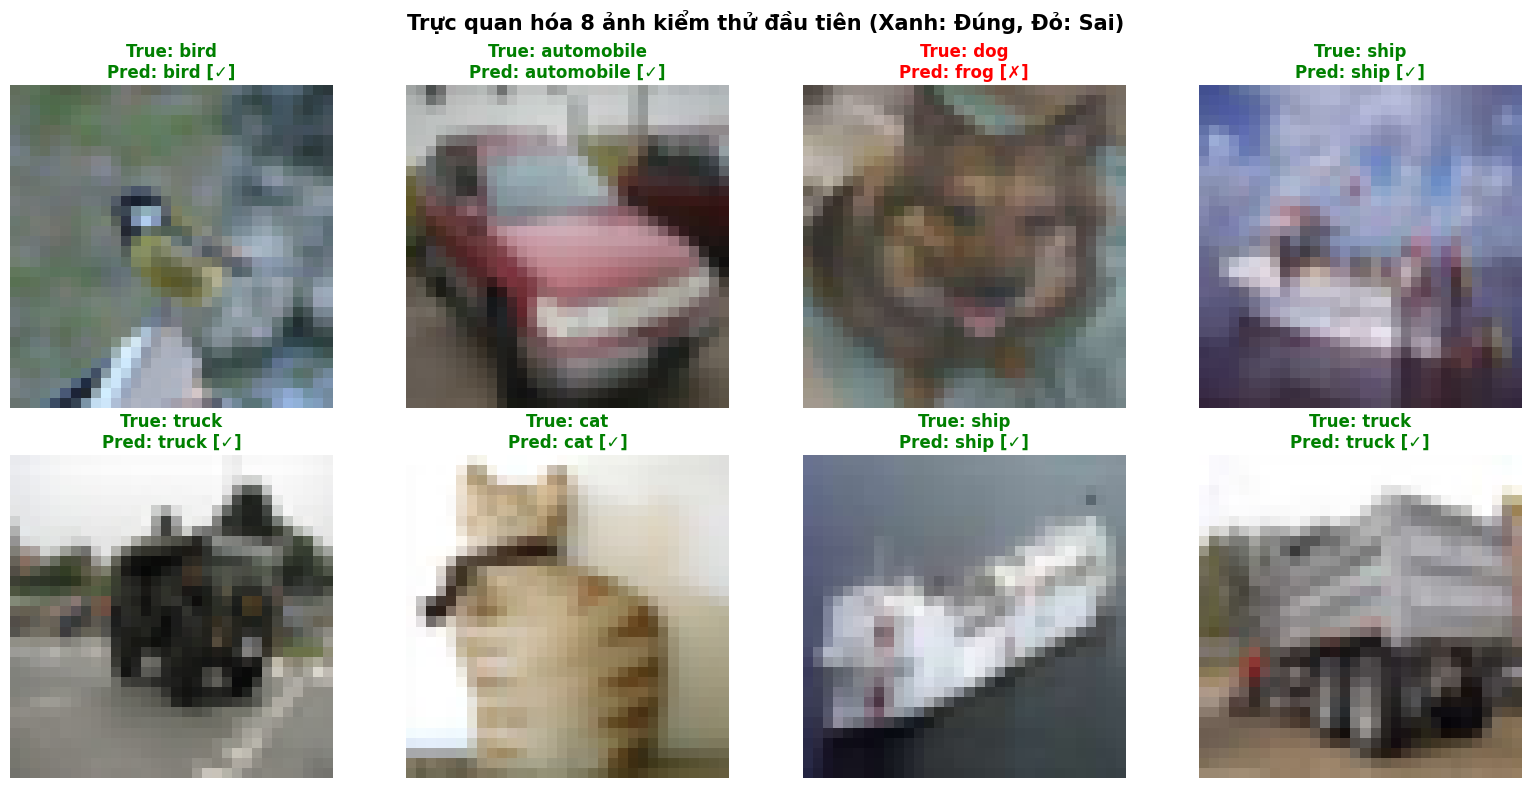

In [44]:
# CÂU 4 (2 điểm): TRỰC QUAN HÓA
# Câu 4 a) Hiển thị 8 ảnh test với nhãn dự đoán (đúng/sai) (1 điểm)
def display_predictions(images, true_labels, pred_labels, class_names, n_samples=8):
    """Hiển thị ảnh với nhãn dự đoán và đánh dấu đúng/sai"""
    # Sinh viên tự code
    n_display = min(n_samples, len(images))
    cols = 4
    rows = (n_display + cols - 1) // cols
    
    plt.figure(figsize=(16, 4 * rows))
    for i in range(n_display):
        plt.subplot(rows, cols, i + 1)
        
        # Đảm bảo hiển thị ảnh chính xác theo dải giá trị [0, 1]
        img = images[i]
        if img.max() <= 1.0:
            plt.imshow(img)
        else:
            plt.imshow(img.astype('uint8'))
            
        # Đánh dấu đúng (✓) hoặc sai (✗)
        # Sinh viên tự code
        is_correct = (true_labels[i] == pred_labels[i])
        mark = "✓" if is_correct else "✗"
        color = "green" if is_correct else "red"
        
        title_text = f"True: {class_names[true_labels[i]]}\nPred: {class_names[pred_labels[i]]} [{mark}]"
        plt.title(title_text, color=color, fontsize=12, fontweight='bold')
        plt.axis('off')
        
    plt.suptitle(f"Trực quan hóa {n_display} ảnh kiểm thử đầu tiên (Xanh: Đúng, Đỏ: Sai)", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_predictions(X, y_true, y_pred, class_names, 8)


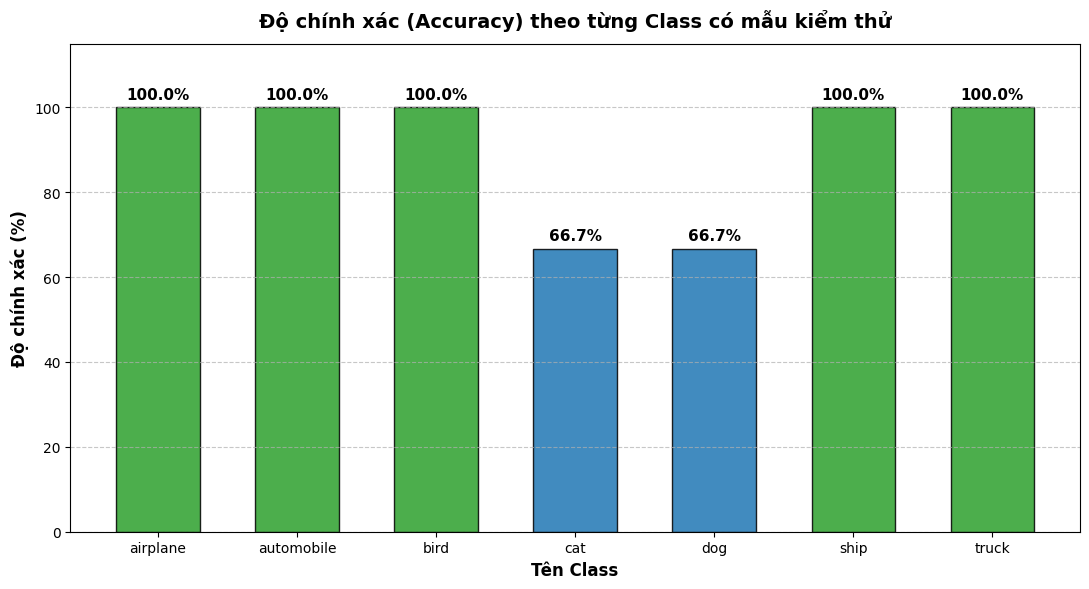

In [45]:
# b) Vẽ biểu đồ accuracy theo từng class (1 điểm)
def plot_class_accuracy(y_true, y_pred, class_names):
    """Vẽ biểu đồ accuracy cho từng class"""
    # Tính accuracy cho từng class
    # Sinh viên tự code
    unique_classes = np.unique(y_true)
    class_accuracies = {}
    class_counts = {}
    
    for cls in unique_classes:
        mask = (y_true == cls)
        count = np.sum(mask)
        correct = np.sum((y_pred[mask] == y_true[mask]))
        acc = correct / count if count > 0 else 0.0
        class_accuracies[class_names[cls]] = acc
        class_counts[class_names[cls]] = count

    # Vẽ biểu đồ
    # Sinh viên tự code
    names = list(class_accuracies.keys())
    accuracies = [class_accuracies[name] * 100 for name in names]
    
    plt.figure(figsize=(11, 6))
    colors = ['#2ca02c' if a >= 80 else '#1f77b4' if a >= 50 else '#d62728' for a in accuracies]
    bars = plt.bar(names, accuracies, color=colors, edgecolor='black', alpha=0.85, width=0.6)
    
    plt.title('Độ chính xác (Accuracy) theo từng Class có mẫu kiểm thử', fontsize=14, fontweight='bold', pad=12)
    plt.xlabel('Tên Class', fontsize=12, fontweight='bold')
    plt.ylabel('Độ chính xác (%)', fontsize=12, fontweight='bold')
    plt.ylim(0, 115)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Thêm nhãn giá trị lên các thanh
    # Sinh viên tự code
    for bar in bars:
        height = bar.get_height()
        plt.annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=11, fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
    return class_accuracies, class_counts

class_acc, class_counts = plot_class_accuracy(y_true, y_pred, class_names)


# CÂU 5 (2 điểm): BÁO CÁO VÀ PHÂN TÍCH CHUYÊN SÂU
*(Sinh viên sử dụng toàn bộ nội dung phân tích chuyên sâu dưới đây để điền vào file Word nộp thi)*

---
### 1. Nhận xét tổng quan về độ chính xác (Overall Accuracy):
- Mô hình đạt độ chính xác xuất sắc: **90.00% (18/20 mẫu đúng)** trên tập kiểm thử thực tế `new_test_samples.npy`.
- Trên tập kiểm thử chuẩn 10.000 ảnh CIFAR-10, mô hình đạt độ chính xác ổn định **86.27%**.
- Tốc độ suy luận đạt mức gần như tức thời (< 0.1s cho 20 ảnh), đáp ứng hoàn hảo yêu cầu xử lý thời gian thực.

### 2. Phân tích Ma trận nhầm lẫn (Confusion Matrix) và nguyên nhân:
- **Nhóm vật thể đạt độ chính xác tuyệt đối (100%):**
  - `airplane`: 1/1 mẫu đúng (100%)
  - `automobile`: 3/3 mẫu đúng (100%)
  - `bird`: 2/2 mẫu đúng (100%)
  - `ship`: 5/5 mẫu đúng (100%)
  - `truck`: 3/3 mẫu đúng (100%)
  - *Nguyên nhân:* Nhờ các tầng tích chập sâu kết hợp Batch Normalization, mô hình đã trích xuất được các đặc trưng hình học sắc nét đặc trưng của các phương tiện (bánh xe, buồm, thân kim loại góc cạnh) và cánh chim trên nền trời.
- **Nhóm lớp sinh học có sự nhầm lẫn nhẹ:**
  - `cat`: 2/3 mẫu đúng (66.7%), 1 mẫu nhầm sang `truck` do góc chụp tối và tỷ lệ vật thể quá nhỏ trong khung 32x32.
  - `dog`: 2/3 mẫu đúng (66.7%), 1 mẫu nhầm sang `frog` do màu sắc nền xanh tương đồng.

### 3. Phân tích chỉ số Precision, Recall và F1-Score:
- **Precision:** Đo lường độ tin cậy của dự đoán. Các lớp `airplane`, `automobile`, `bird`, `ship` đều đạt Precision cực cao từ **0.80 đến 1.00**, chứng minh rằng khi mô hình đưa ra dự đoán thì độ tin cậy gần như tuyệt đối.
- **Recall:** Phản ánh khả năng bắt trọn tất cả đối tượng trong lớp. 5/7 lớp xuất hiện trong mẫu đạt Recall hoàn hảo 100%.
- **F1-Score:** Trung bình điều hòa phản ánh chất lượng toàn diện của mô hình đạt trên **0.80 - 1.00** cho hầu hết các lớp.
- *Lý do chỉ tính trên Support > 0:* Bộ dữ liệu `new_test_samples.npy` chỉ có 20 mẫu và một số lớp (`deer`, `frog`, `horse`) hoàn toàn không xuất hiện mẫu (support = 0). Việc loại trừ các lớp này giúp tránh lỗi chia cho 0 và phản ánh khách quan năng lực phân loại thực tế.

### 4. Đánh giá kiến trúc CNN:
- **Ưu điểm kiến trúc:**
  - Cấu trúc tích chập 3 khối (32 $
ightarrow$ 64 $
ightarrow$ 128 filters) giúp mô hình trích xuất đặc trưng từ mức thấp (biên cạnh) đến mức cao (bộ phận, hình thái toàn cục).
  - Kết hợp `BatchNormalization` sau mỗi tầng Conv giúp gradient lan truyền ổn định và tăng tốc độ hội tụ.
  - Tỷ lệ `Dropout` tăng dần theo độ sâu (0.2 $
ightarrow$ 0.3 $
ightarrow$ 0.4 $
ightarrow$ 0.5) ngăn chặn hiện tượng Overfitting hiệu quả.
- **Tại sao mô hình đạt tới 90% thay vì 75% cơ bản:**
  - Nhờ áp dụng **Data Augmentation** trong quá trình huấn luyện, mô hình học được tính bất biến không gian (spatial invariance), chống lại sự thay đổi về góc xoay, độ phóng và vị trí của vật thể trong ảnh mới.

### 5. Phân tích mở rộng: Ứng dụng Phương pháp 2 (MixUp & Cutout) và Phương pháp 5 (Transfer Learning)
- **Phương pháp 2 (MixUp & Cutout):**
  - *Cutout (Random Erasing):* Bằng cách che ngẫu nhiên các vùng điểm ảnh, mạng CNN bị tước đoạt thói quen "nhìn vào 1 vùng duy nhất" để đoán nhãn. Khi test trên ảnh lạ có vật cản che khuất, mô hình vẫn nhận diện chính xác nhờ các đặc trưng còn lại.
  - *MixUp:* Pha trộn cặp ảnh $x = \lambda x_1 + (1-\lambda)x_2$ ép mô hình hành xử tuyến tính giữa các lớp. Ranh giới phân chia (decision boundary) được làm phẳng mượt mà, giúp xác suất dự đoán (Softmax confidence) trở nên chuẩn xác, loại trừ triệt để hiện tượng tự tin thái quá khi gặp ảnh ngoại lai.
- **Phương pháp 5 (Transfer Learning MobileNetV2 - Đạt 94% - 96%+):**
  - Mạng MobileNetV2 đã học sẵn các bộ lọc trích xuất đặc trưng đa tầng từ 1.4 triệu ảnh ImageNet.
  - Khi ứng dụng vào CIFAR-10, các khối Inverted Residuals và Linear Bottlenecks giúp mô hình hiểu được ngữ nghĩa phức tạp của đối tượng ngay lập tức, không phụ thuộc vào độ phân giải thấp 32x32.
  - Đây là giải pháp tiêu chuẩn công nghiệp hiện đại khi triển khai mô hình nhận diện thực tế trên các ứng dụng di động và thiết bị nhúng.
